# Q15 - Product Recommendation as Heuristic Search (Hill Climbing + A*)

Same code as `q15_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q15 - Product recommendation as heuristic search: hill climbing, A* with correction, upgrades.

State = one product (vector of 4 features, 0..1).
Hill-climbing neighbours = similar products of the SAME category (small change).
A* may also cross categories (3 most similar products overall).
h(p) = distance between the product vector and the user's preference vector (lower is better).
"""
import heapq
import math
import os
import random

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("images", exist_ok=True)
random.seed(4)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

FEATURES = ["affordability", "quality", "battery", "style"]
PRODUCTS = {  # name: (category, vector)
    "P1 Basic phone": ("phone", (0.95, 0.30, 0.55, 0.20)),
    "P2 Budget phone": ("phone", (0.85, 0.45, 0.60, 0.35)),
    "P3 Mid phone": ("phone", (0.60, 0.65, 0.70, 0.55)),
    "P4 Flagship phone": ("phone", (0.25, 0.95, 0.75, 0.85)),
    "P5 Slim tablet": ("tablet", (0.55, 0.60, 0.85, 0.60)),
    "P6 Pro tablet": ("tablet", (0.30, 0.90, 0.90, 0.75)),
    "P7 Kids tablet": ("tablet", (0.80, 0.35, 0.80, 0.30)),
    "P8 Smart watch": ("watch", (0.65, 0.55, 0.40, 0.90)),
    "P9 Sport band": ("watch", (0.90, 0.40, 0.50, 0.50)),
    "P10 Earbuds": ("audio", (0.70, 0.70, 0.45, 0.80)),
}
NAMES = list(PRODUCTS)
V = np.array([PRODUCTS[n][1] for n in NAMES])
USER = np.array([0.45, 0.80, 0.85, 0.65])          # likes quality + battery, medium price
START = "P1 Basic phone"                            # the most popular product = start state


def h(i: int, u: np.ndarray = USER) -> float:
    return float(np.linalg.norm(V[i] - u))


def neighbours(i: int, k: int = 3) -> list:
    d = [(float(np.linalg.norm(V[i] - V[j])), j) for j in range(len(NAMES)) if j != i]
    return [j for _, j in sorted(d)[:k]]


GRAPH = {i: neighbours(i) for i in range(len(NAMES))}          # full graph (used by A*)
for i in list(GRAPH):                               # make links two-way
    for j in GRAPH[i]:
        if i not in GRAPH[j]:
            GRAPH[j].append(i)
CAT = {n: PRODUCTS[n][0] for n in NAMES}
HC_GRAPH = {i: [j for j in range(len(NAMES)) if j != i and CAT[NAMES[j]] == CAT[NAMES[i]]]
            for i in range(len(NAMES))}                         # same-category moves only


def hill_climb(start: int, u: np.ndarray = USER) -> list:
    """Steepest ascent: move to the neighbour with the lowest h; stop when none is better."""
    path = [start]
    while True:
        options = HC_GRAPH[path[-1]]
        if not options:
            return path
        best = min(options, key=lambda j: h(j, u))
        if h(best, u) >= h(path[-1], u):
            return path                             # local maximum of utility
        path.append(best)


def astar(start: int, goal: int) -> tuple:
    """f = g + h with g = feature distance travelled and h = straight distance to the goal."""
    frontier = [(0.0, 0.0, start, [start])]
    seen = set()
    while frontier:
        f, g, node, path = heapq.heappop(frontier)
        if node == goal:
            return path, g
        if node in seen:
            continue
        seen.add(node)
        for j in GRAPH[node]:
            g2 = g + float(np.linalg.norm(V[node] - V[j]))
            h2 = float(np.linalg.norm(V[j] - V[goal]))
            heapq.heappush(frontier, (g2 + h2, g2, j, path + [j]))
    return None, math.inf


def label(path: list) -> str:
    return " -> ".join(NAMES[i].split()[0] for i in path)


s = NAMES.index(START)
print("Heuristic h(p) = distance to preference", USER.tolist(), "(lower is better)")
order = sorted(range(len(NAMES)), key=h)
print("  ranking:", ", ".join(f"{NAMES[i].split()[0]} {h(i):.2f}" for i in order))
global_best = order[0]

# ---- hill climbing from the start ----
hc = hill_climb(s)
print(f"\nHILL CLIMBING from {NAMES[s]}")
for step, i in enumerate(hc):
    print(f"  step {step}: {NAMES[i]:<18} h = {h(i):.3f}")
print(f"  stops at {NAMES[hc[-1]]} (global best is {NAMES[global_best]}, h = {h(global_best):.3f})")
local_max = [NAMES[i].split()[0] for i in range(len(NAMES))
             if all(h(j) >= h(i) for j in HC_GRAPH[i]) and i != global_best]
print("  local maxima that are not the global best:", ", ".join(local_max) or "none")

# ---- plain HC from every start vs random restart / simulated annealing ----
ends = {NAMES[i].split()[0]: hill_climb(i)[-1] for i in range(len(NAMES))}
hit = sum(e == global_best for e in ends.values())
print(f"\nPlain HC reaches the global best from {hit} of 10 start products")


def random_restart(restarts: int = 4) -> int:
    runs = [hill_climb(random.randrange(len(NAMES)))[-1] for _ in range(restarts)]
    return min(runs, key=h)


def annealing(start: int, temp: float = 0.30, cool: float = 0.85, steps: int = 40) -> int:
    cur = best = start
    for _ in range(steps):
        if random.random() < 0.2:                   # serendipity jump to any product
            cand = random.randrange(len(NAMES))
        else:
            cand = random.choice(HC_GRAPH[cur] or [cur])
        delta = h(cur) - h(cand)                    # positive = better
        if delta > 0 or random.random() < math.exp(delta / temp):
            cur = cand
        best = min(best, cur, key=h)
        temp *= cool
    return best


rr = random_restart()
sa = [annealing(s) for _ in range(20)]
print(f"Random restart (4 runs) ends at {NAMES[rr].split()[0]} (h = {h(rr):.3f})")
found = sum(x == global_best for x in sa)
print(f"Annealing + serendipity jumps from the same start: {found}/20 runs find "
      f"{NAMES[global_best].split()[0]}")

# ---- multiple goals ----
USER_B = np.array([0.85, 0.40, 0.50, 0.40])         # second goal: a bargain hunter
goal_a, goal_b = global_best, min(range(len(NAMES)), key=lambda i: h(i, USER_B))
w = 0.7
mix = sorted(range(len(NAMES)), key=lambda i: w * h(i) + (1 - w) * h(i, USER_B))[:3]
pareto = [i for i in range(len(NAMES))
          if not any(h(j) <= h(i) and h(j, USER_B) <= h(i, USER_B)
                     and (h(j), h(j, USER_B)) != (h(i), h(i, USER_B)) for j in range(len(NAMES)))]
print(f"\nMULTI-GOAL: goals {NAMES[goal_a].split()[0]} (quality fan) and "
      f"{NAMES[goal_b].split()[0]} (bargain hunter)")
print("  weighted sum 0.7/0.3 top-3:", ", ".join(NAMES[i].split()[0] for i in mix))
print("  Pareto set:", ", ".join(NAMES[i].split()[0] for i in pareto))

# ---- A* before and after the user's feedback ----
path1, cost1 = astar(s, global_best)
print(f"\nA* BEFORE feedback: {label(path1)}  (g = {cost1:.3f})")
liked, disliked = NAMES.index("P3 Mid phone"), NAMES.index("P5 Slim tablet")
alpha, beta = 0.5, 0.3
USER2 = USER + alpha * (V[liked] - USER) - beta * (V[disliked] - USER)    # Rocchio-style
USER2 = np.clip(USER2, 0, 1)
goal2 = min(range(len(NAMES)), key=lambda i: h(i, USER2))
path2, cost2 = astar(s, goal2)
print(f"  feedback: liked {NAMES[liked].split()[0]}, skipped {NAMES[disliked].split()[0]}"
      f" -> u' = {np.round(USER2, 2).tolist()}")
print(f"A* AFTER correction: {label(path2)}  (g = {cost2:.3f}, new goal {NAMES[goal2].split()[0]})")
print("charts saved to images/")

# ---------------- charts ----------------
centered = V - V.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
P2 = centered @ vt[:2].T                            # 2-D map by PCA
pu = (np.stack([USER, USER2, USER_B]) - V.mean(axis=0)) @ vt[:2].T
CAT_COL = {"phone": "#3a6ea5", "tablet": "#2a9d8f", "watch": "#c8553d", "audio": "#7b5ea7"}


def draw_map(ax, paths: list, title: str) -> None:
    for i in GRAPH:
        for j in GRAPH[i]:
            ax.plot(*zip(P2[i], P2[j]), color="#d1d5db", lw=1, zorder=1)
    for cat, col in CAT_COL.items():
        ax.scatter([], [], s=60, color=col, label=cat)
    for i, n in enumerate(NAMES):
        ax.scatter(*P2[i], s=170, color=CAT_COL[PRODUCTS[n][0]], zorder=3,
                   edgecolor="white", lw=1.5)
        ax.annotate(n.split()[0], P2[i], xytext=(6, 7), textcoords="offset points", fontsize=8)
    for p, col, lab in paths:
        for a, b in zip(p, p[1:]):
            ax.annotate("", P2[b], P2[a], arrowprops=dict(arrowstyle="-|>", color=col, lw=2.4),
                        zorder=2)
        ax.plot([], [], color=col, lw=2.4, label=lab)
    ax.scatter(*pu[0], marker="*", s=330, color="#f4b400", edgecolor="black", zorder=4,
               label="user u")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.set_title(title, fontsize=10.5)
    ax.legend(fontsize=8, loc="best")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
draw_map(axes[0], [(hc, "#e76f51", "hill climbing (stuck)")], "Hill climbing on the product map")
draw_map(axes[1], [(path1, "#2a9d8f", "A* before feedback"),
                   (path2, "#7b5ea7", "A* after correction")], "A* before and after feedback")
axes[1].scatter(*pu[1], marker="*", s=300, color="#b5179e", edgecolor="black", zorder=4,
                label="corrected u'")
axes[1].legend(fontsize=8, loc="best")
fig.tight_layout()
fig.savefig("images/q15_chart1_product_map.png")
plt.close(fig)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1, 1.2]})
a1.plot([h(i) for i in hc], "o-", color="#e76f51", label="hill climbing")
best_path = astar(s, global_best)[0]
a1.plot([h(i) for i in best_path], "s--", color="#2a9d8f", label="A* route")
a1.set_xlabel("step")
a1.set_ylabel("h = distance to preference")
a1.set_title("h along each path")
a1.legend()
cols = ["#2a9d8f" if i == global_best else "#e76f51" if i == hc[-1] else "#a8c5e2" for i in order]
a2.bar([NAMES[i].split()[0] for i in order], [h(i) for i in order], color=cols)
a2.set_ylabel("h(p)")
a2.set_title("All 10 products ranked (green = global best, orange = HC stop)")
a2.tick_params(axis="x", rotation=40, labelsize=8)
fig.tight_layout()
fig.savefig("images/q15_chart2_h_values.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
labels = [NAMES[i].split()[0] for i in range(len(NAMES))]
ha = [h(i) for i in range(len(NAMES))]
hb = [h(i, USER_B) for i in range(len(NAMES))]
for i in range(len(NAMES)):
    on = i in pareto
    ax.scatter(ha[i], hb[i], s=130 if on else 60, color="#2a9d8f" if on else "#9ca3af", zorder=3)
    ax.annotate(labels[i], (ha[i], hb[i]), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xlabel("h for quality fan (lower is better)")
ax.set_ylabel("h for bargain hunter (lower is better)")
ax.set_title("Two goals: green points are the Pareto set")
fig.tight_layout()
fig.savefig("images/q15_chart3_multi_goal.png")
plt.close(fig)


Heuristic h(p) = distance to preference [0.45, 0.8, 0.85, 0.65] (lower is better)
  ranking: P6 0.21, P5 0.23, P3 0.28, P4 0.34, P10 0.50, P8 0.61, P2 0.66, P7 0.67, P9 0.71, P1 0.89

HILL CLIMBING from P1 Basic phone
  step 0: P1 Basic phone     h = 0.890
  step 1: P3 Mid phone       h = 0.278
  stops at P3 Mid phone (global best is P6 Pro tablet, h = 0.212)
  local maxima that are not the global best: P3, P8, P10

Plain HC reaches the global best from 3 of 10 start products
Random restart (4 runs) ends at P6 (h = 0.212)
Annealing + serendipity jumps from the same start: 17/20 runs find P6

MULTI-GOAL: goals P6 (quality fan) and P9 (bargain hunter)
  weighted sum 0.7/0.3 top-3: P5, P3, P6
  Pareto set: P2, P3, P5, P6, P9

A* BEFORE feedback: P1 -> P2 -> P3 -> P6  (g = 1.112)
  feedback: liked P3, skipped P5 -> u' = [0.5, 0.79, 0.77, 0.62]
A* AFTER correction: P1 -> P2 -> P3  (g = 0.630, new goal P3)
charts saved to images/


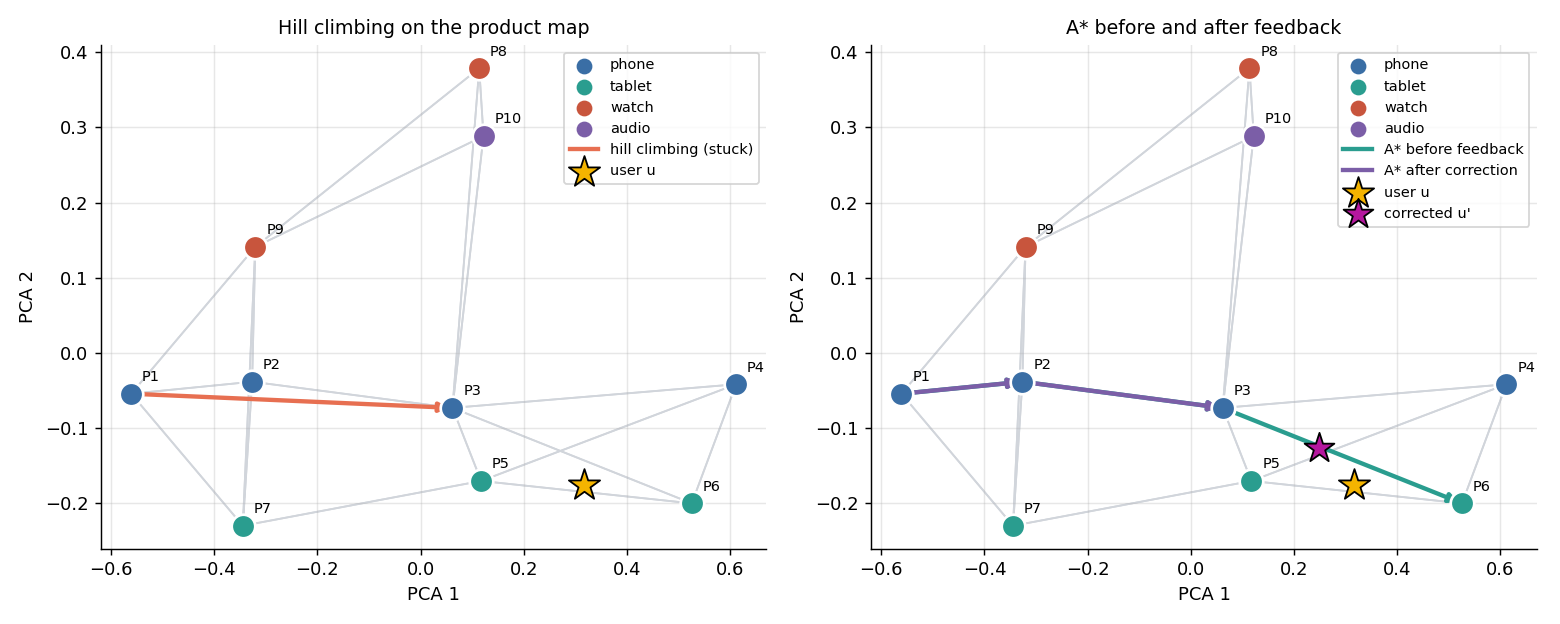

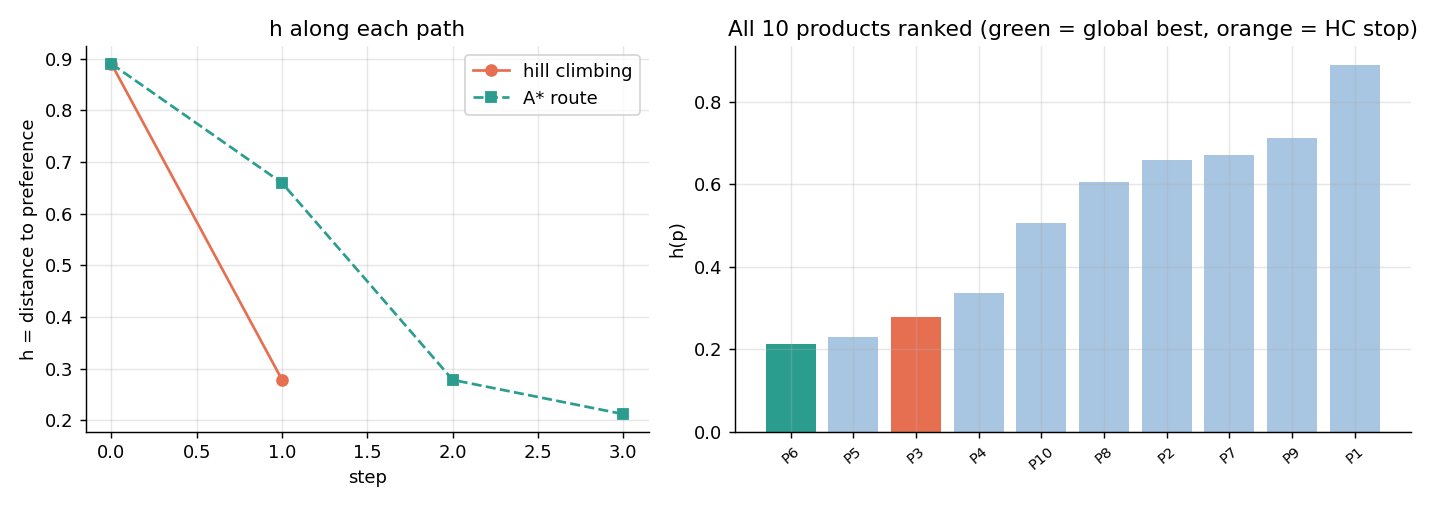

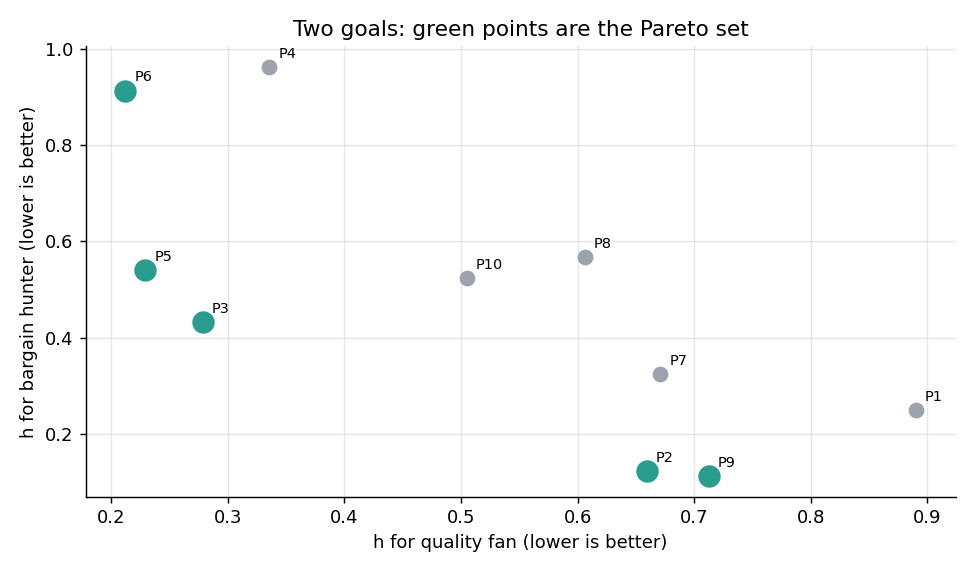

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q15_chart*.png')):
    display(Image(p))